> **You are running this notebook in your browser.** Your changes are saved in this browser only. At the end of class, choose **File → Download** to keep a copy of your work.

In [ ]:
# Browser setup (added automatically): installs plotting support and lets the notebook load data from the web.
%pip install -q seaborn pyodide-http
import pyodide_http
pyodide_http.patch_all()


# Welcome to Talking Trees Day 1! - alter text later
In this colab notebook, we will be investigating how environmental factors change during a drought in the Amazon. We will do this by comparing data of several different environmental factors (like temperature, rain, and humidity) from a drought year versus those same factors during a non-drought year in the Amazon.


---



In [ ]:
# DO NOT EDIT THIS BLOCK

# @title Click Play to Run Setup

# Load in the packages/libraries
# Packages and libraries contain functions which will perform certain actions in code
import hashlib
import pandas as pd # to manipulate data
import numpy as np # for mathematical operations
from cycler import cycler
import matplotlib.pyplot as plt # for plotting
import seaborn as sns # for plotting




# Define environmental variables
env_vars = ['temp', 'light', 'rain', 'humidity']

# Define a consistent color palette for variables
variable_colors = {
    'temp': '#a6cee3',
    'light': '#1f78b4',
    'rain': '#b2df8a',
    'humidity': '#33a02c',
    'VPD' : '#fdbf6f',
    'sf.itauba': '#fb9a99',
    'sf.erisma': '#e31a1c',
    'Itauba' : '#fb9a99',
    'Erisma' : '#e31a1c',
    'Other species' : '#fdbf6f'
}





# Load in the custom functions

## Create a function to load in data without worrying about file paths

# Load data directly into Python (into RAM) from public download link.
# - You need to turn the share link that looks like this: https://drive.google.com/file/d/FILE_ID/view?usp=sharing
#   -- ...into a download link that looks like this: https://drive.google.com/uc?export=download&id=FILE_ID
#   -- I.e. start with https://drive.google.com/ , add uc?export=download&id= , then the share-link text between "/d/" and "/view?" (here "FILE_ID").
# Dataset share link: https://drive.google.com/file/d/1GenDfhfqKDPM_AcG8eJyrzOxDuMz7vTL/view?usp=drive_link
# Dataset download URL

def load_data(dataset):
  if dataset == "environment_data_subset":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_subset":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_all":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'VPD', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "stomata_data":
    url = "https://lawrence-hall-of-science.github.io/talking-trees/data/Stomata_Species_prc-250602.csv"
    df = pd.read_csv(url)
    # rename the columns
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'st.length', 'st.dens']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    # Make a 'species category' column
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    # Convert mm to m
    df['st.length'] = df['st.length']/1000
    df['st.dens'] = df['st.dens']*1000*1000
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  elif dataset == "xylem_data":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Xylem_Species_prc-240216.csv'
    df = pd.read_csv(url)
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'diam.avg', 'area.avg', 'diam.max', 'ves.dens', 'rel.lum.area']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  else:
    print("Dataset not found. Please input a valid dataset name.")

  data = df[cols]
  print("Data Loaded Successfully")
  print(len(data), " rows of data loaded")
  return data


## Function to the the monthly summary for environmental data
def get_monthly_summary(data, vars = env_vars) :

  cols = ['year', 'month', 'hour'] + vars
  data = data[cols]

  if 'rain' in data.columns:
    # Do rain first since it doesn't get filtered to daytime values
    dat_mo = data.groupby(['year', 'month'])['rain'].sum().reset_index()

  # isolate daytime values for everything except for rain
  idl = (data['hour'] > 9) & (data['hour'] < 17)

  if 'rain' in data.columns:
    vars = [v for v in vars if v != "rain"] # make sure it's all the variables but rain

  # Group the data so we get averages for each month in each year separately
  dat_mo2 = data.loc[idl].groupby(['year', 'month'])[vars].mean().reset_index()

  # Put rain and the other variables back together in the same table
  if 'rain' in data.columns:
    dat_mo_combo = pd.merge(dat_mo, dat_mo2, how = "right", on = ["year", "month"])
  else:
    dat_mo_combo = dat_mo2


  # Add in the labels for drought condition for each year -- may not need if this column is already in the dataset
  dat_mo_combo['yr_label'] = 'Normal'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2015, 'yr_label'] = 'Drought'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2016, 'yr_label'] = 'Post-Drought'

  return dat_mo_combo


# Plotting function for monthly trends across years
def plot_monthly_data(data, vars = env_vars, years = ['Normal'], xaxis = 'month'):

  # Make our basic plot, with enough subplots for each variable
  fig, axs = plt.subplots(len(vars), 1, sharex=True, figsize=(6, 8))

  # Loop through variables to create plots - this will make one subplot for each variable we put into it
  for i, var in enumerate(vars):
    # Make a title for each plot
      title = f"Monthly average of {var} over the course of a year"
      axs[i].set_title(title)
      # Make a lineplot for each variable, for each year
      sns.lineplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = True)
      # Add points to each graph
      sns.scatterplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = False)
      # Shade the wet season
      axs[i].axvspan(1, 7, facecolor = "grey", alpha = 0.2)

  # Create a proxy artist for the wet season label
  wet_season_patch = plt.matplotlib.patches.Rectangle((0,0), 1, 1, facecolor="grey", alpha=0.2, label='Wet Season')

  # Apply a common legend
  handles, labels = axs[0].get_legend_handles_labels()  # Get legend from first plot
  custom_labels = years
  handles.append(wet_season_patch) # Add the wet season patch to the handles
  custom_labels.append('Wet Season') # Add the wet season label

  fig.legend(handles, custom_labels, loc = 'right', title = "Year", bbox_to_anchor = (1.3, 0.5)) # set it on the right side
  for i, fig in enumerate(vars):
    axs[i].get_legend().remove() # Remove the legends from each individual plot
  plt.tight_layout()  # Adjust layout to prevent overlap
  plt.show()



# Function to plot N random days of diurnal data

def graph_diurnals(data, n_days = 6, vars = ['temp', 'light'], title = '') :

  # Subset data and order factor levels to plot in order specificed in env_vars
  # Make sure vars is in the right format

  # Prepare the data for plotting
  # Select all the columns we want
  cols = ['date', 'hour', 'month'] + vars + ['sf.erisma', 'sf.itauba']
  # Pick dates from 2014
  dat_d = pd.melt(data[data['year'] == 2014][cols], id_vars = ['date', 'hour', 'month'])
  dat_d['variable'] = dat_d['variable'].astype('category')
  # Remove all the nighttime data
  dat_final = dat_d[(dat_d['hour'] >= 5) & (dat_d['hour'] <= 20)]

  # Ensure the variables we want to plot are actually in the dat_d dataframe columns
  # This prevents errors if a variable name is mistyped or not present
  valid_vars = [v for v in vars if v in dat_final['variable'].unique()] + ['sf.erisma', 'sf.itauba']
  sub = dat_final[dat_final['variable'].isin(valid_vars)].copy()
  if sub.empty:
      print("Error: No data available for the specified variables and dates.")
      return # Exit the function if there's no data to plot

  # Add a column for the wet and dry season
  sub['season'] = 'dry'
  sub.loc[(sub['month'] >= 1) & (sub['month'] <= 7), 'season'] = 'wet'


  # Pick a random sample of days from the chosen year
  # Half will be from the wet season and half from the dry season
  sub['variable'] = pd.Categorical(sub['variable'], categories = valid_vars)
  sub_wet = sub[sub['season'] == 'wet']
  sub_dry = sub[sub['season'] == 'dry']
  unique_dates_wet = sub_wet['date'].unique()
  unique_dates_dry = sub_dry['date'].unique()
  n_days_dry = round(n_days/2)
  n_days_wet = n_days - n_days_dry
  sampled_dates_wet = np.random.choice(unique_dates_wet, size= n_days_wet, replace=False)
  sampled_dates_dry = np.random.choice(unique_dates_dry, size= n_days_dry, replace=False)
  sub_sampled_days_wet = sub[sub['date'].isin(sampled_dates_wet)].copy()
  sub_sampled_days_dry = sub[sub['date'].isin(sampled_dates_dry)].copy()
  # Ensure sub_sampled_days only contains the selected dates and variables
  sub_sampled_days_wet = sub_sampled_days_wet[sub_sampled_days_wet['variable'].isin(valid_vars)]
  sub_sampled_days_dry = sub_sampled_days_dry[sub_sampled_days_dry['variable'].isin(valid_vars)]
  # Merge the wet and the dry back together
  sub_sampled_days = pd.concat([sub_sampled_days_wet, sub_sampled_days_dry])

  # Determine the layout of the subplots: columns = dates, rows = variables

  # Separate the sf.itauba and sf.erisma variables to plot them together
  sf_vars = ['sf.itauba', 'sf.erisma']
  other_vars = [v for v in valid_vars if v not in sf_vars]
  plot_vars = other_vars + ['sapflow'] # Add a placeholder for the combined sapflow plot

  n_cols = len(sub_sampled_days['date'].unique())
  n_rows = len(plot_vars)
  fig, axs = plt.subplots(n_rows, n_cols, sharex=True, figsize=(12, 10))

  # Ensure all the y axes are on the same scale per varaible
  # Make this the same for all days, not just the ones selected
  y_limits = {
    var: (
      dat_final[dat_final['variable'] == var]['value'].min(),
      dat_final[dat_final['variable'] == var]['value'].max()
    )
    for var in valid_vars
  }

  # Make plots for each varable-date combination
  for i, var in enumerate(plot_vars):
    for j, date in enumerate(sub_sampled_days['date'].unique()):
      ax = axs[i,j]
      if var == 'sapflow':
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'].isin(sf_vars))]
          sns.lineplot(data=subset, x='hour', y='value', ax=ax, hue='variable', legend=False, palette=variable_colors) # Remove legend from subplot
          # Set y-axis limits for sapflow variables
          min_sf = min(y_limits['sf.itauba'][0], y_limits['sf.erisma'][0])
          max_sf = max(y_limits['sf.itauba'][1], y_limits['sf.erisma'][1])
          ax.set_ylim(min_sf, max_sf)
      else:
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'] == var)]
          sns.lineplot(data=subset, x = 'hour', y = 'value', ax=ax, hue = 'variable', legend = False, palette=variable_colors) # Remove legend from subplot
          ax.set_ylim(y_limits[var])

  # Set the axes labels
  for i, var in enumerate(plot_vars):
      label = 'Sapflow' if var == 'sapflow' else var
      axs[i, 0].set_ylabel(f'{label}', fontsize=12, rotation=0, labelpad=50)
  for j, date in enumerate(sub_sampled_days['date'].unique()):
    axs[0, j].set_title(f'{date}', fontsize=12, pad = 20)

  # Add a single legend for the entire figure
  # Get handles and labels for all variables
  all_handles = []
  all_labels = []
  for var in other_vars:
      # Create a proxy artist for each individual variable
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[var], lw=2))
      all_labels.append(var)

  # Create proxy artists for the sapflow variables
  for sf_var in sf_vars:
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[sf_var], lw=2))
      all_labels.append(sf_var)

  fig.legend(all_handles, all_labels, loc='right', title='Variable', bbox_to_anchor=(1.2, 0.5))

  plt.tight_layout()
  plt.show()


## Custom function for calculating the stomatal conductive capacity
def calc_gw_max(data, length = 'st.length', density = 'st.dens') :
    length = data[length]
    density = data[density]
    pi = 3.14159265359
    d = 0.0000249
    v = 0.0224
    A = 0.12 * length * length/2
    l = length/4
    gw_max = (d * (density/v)) * (A / (l + (0.5 * ((pi * A)**0.5))))
    return gw_max



print("Setup Run Correctly!")


Setup Run Correctly!


## Loading Dataset

Now, we need to load in our dataset so that we can work with it. We'll be working with a dataset called "environment_sapflow_data_subset".

In [ ]:
# Let's load in our data and save it as an object called "climate"
sapflow = load_data(dataset = "environment_sapflow_data_subset")

# Troubleshoot: If tyou get an error message, go back up to the setup section and press the play button to run it

Data Loaded Successfully
52608  rows of data loaded


Congrats! We've loaded our dataset and saved it as an object called 'data'. From now on, the computer knows that 'data' specifically refers to our dataset.

Now, rather than trying to inspect the all 52,608 rows of our dataset at once, let's just look at the first 5 rows. We can do this using a ***function*** called 'head()'. First, we start with our dataset name (*climate*), then type '.head()'. The number inside the parentheses is the number of rows we want to see.


In [ ]:
# Look at the first five rows of the table
sapflow.head(5)

### Bonus Question 1: How do you think you could change the code to look at the first 10 rows of our data? Feel free to try it!
### Bonus Question 2: How do you think you could change the code to look at the last 5 rows of our data? (hint: think about coins - what is the opposite of heads?) Feel free to try it!

,date,year,month,hour,temp,light,rain,humidity,yr.label,sf.itauba,sf.erisma
0,2014-01-01,2014,1,0.0,26.004257,0.0,0.0,87.056423,Normal,0.028277,0.004453
1,2014-01-01,2014,1,0.5,25.535532,0.0,0.0,88.227500,Normal,0.002067,0.001142
2,2014-01-01,2014,1,1.0,25.058028,0.0,0.0,89.671820,Normal,0.001554,0.002101
3,2014-01-01,2014,1,1.5,24.662494,0.0,0.0,90.368769,Normal,0.000345,0.002418
4,2014-01-01,2014,1,2.0,24.331351,0.0,0.0,90.931979,Normal,0.000000,0.002712


## Data Analysis

For today, we're interested in how the environment changes throughout the year in the Amazon, as well as how these are different between a normal year and a drought year. If you look at the columns in *climate*, you'll see that the environmental variables we have are temperature (*temp*), sunlight (*light*), precipitation (*rain*), and humidity (*humidity*).

In [ ]:
# First, let's pick our environmental variables of interest. These will have the same names
# as the environmental columns in our dataset. We type these in brackets [], with
# each column name in quotes '' and each environmental variable separated by a comma ,

env_vars = ['temp', 'light', 'rain'] # <-- Change this to include any environmental variables you think will vary between drought and non-drought (normal) years

Now that you've selected some environmental variables to investigate, we'll take a look at how they vary through the course of a day. We'll do this by using the function **graph_diurnals()** to graph the diurnal (or daily) data. The arguments (*arguments* is the term for what you put inside of a function) of graph_dirunals() are:

*   The data you're working with (*climate*)
*   The environmental variables you want to investigate (*vars*)
*   The number of days you want to look at (*n_days*)

The graph_diurnals() function also plots the *sapflow* of Erisma and Itauba for each day.

To run this function, we'll need to specify the datatable we want to use (which you saved as data) and the environmental variables we want to look at, which we saved as env_vars. So, below in the code cell you'll see that we assigned our datatable, data, to the *data* argument and our  env_vars to the *vars* argument using an equals sign =.

***we may need to do something about the x-axis since it may not be intuitive that hour 0 is 12 am. Either we should edit the axis to be time, or we should explain it in text. The dates are also in year-month-day format, which we may need to think about***

### Graphing Daily Data (Diurnals)

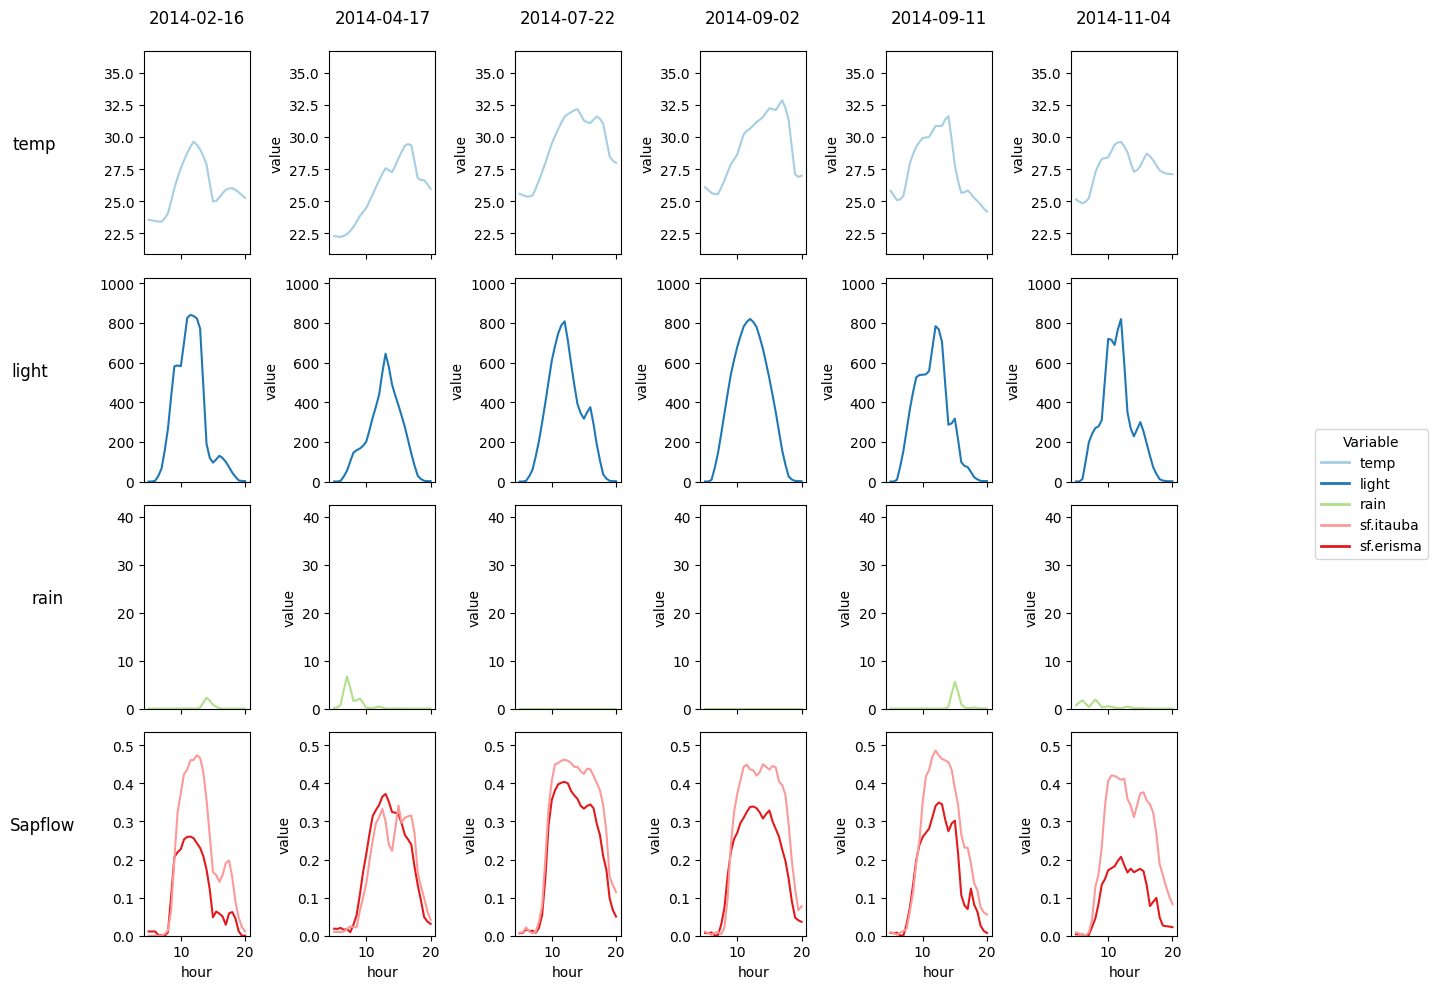

In [ ]:
graph_diurnals(data = sapflow, vars = env_vars, n_days = 6)

In [ ]:
len(climate).rain[climate.rain>25]) ### troubleshooting - delete later

22

What do you notice about the dailiy (or diurnal) pattern of the environment? What about the sapflow?

***insert other learning questions here***

Now that we've taken a look at the patterns throught the day, let's see what they look like throughout the year.

### Graphing Data for the Year

The get_monthly_summary() function will take all the hourly data and average it over each month to let us see how our measurments change over a year. The arguments for get_monthly_summary() are the data (*climate*) and the environmental variables we want to use (*vars*).

Like before, we'll assign the data table (*climate*) to the *data* argument and the list of environmental variables (env_vars) to the *vars* argument.

We'll also want to save the output of this function as a new object so we can work with it later. We'll call this new object data_month.

In [ ]:
# What are the monthly averages? We'll find these using the function
# get_monthly_summary(). The arguments will be the data (climate) and the environmental
# variables we want to look at (vars). We'll call this object 'data_month'

sapflow_month = get_monthly_summary(data = sapflow, vars = env_vars)

# Now take a look at the first ten rows of our data
# It's ALWAYS good practice to look at your data tables before you start messing with them!
sapflow_month.head(10)

,year,month,rain,temp,light,yr_label
0,2014,1,547.021024,28.103090,493.588596,Normal
1,2014,2,1377.887204,27.110868,440.774309,Normal
2,2014,3,999.515369,27.753086,487.716796,Normal
3,2014,4,1117.979475,27.338733,390.823139,Normal
4,2014,5,667.092511,28.114607,396.469541,Normal
5,2014,6,407.784890,29.221922,481.586004,Normal
6,2014,7,334.595286,29.235067,478.710313,Normal
7,2014,8,157.028407,30.684951,626.672052,Normal
8,2014,9,308.683940,30.187172,515.472235,Normal
9,2014,10,23.870902,31.288328,630.798337,Normal


That's a lot of numbers! Our new data table is showing us the average value per month for all the environmental variables we chose

Now let's take a look at what the environment looks like during a Normal year.

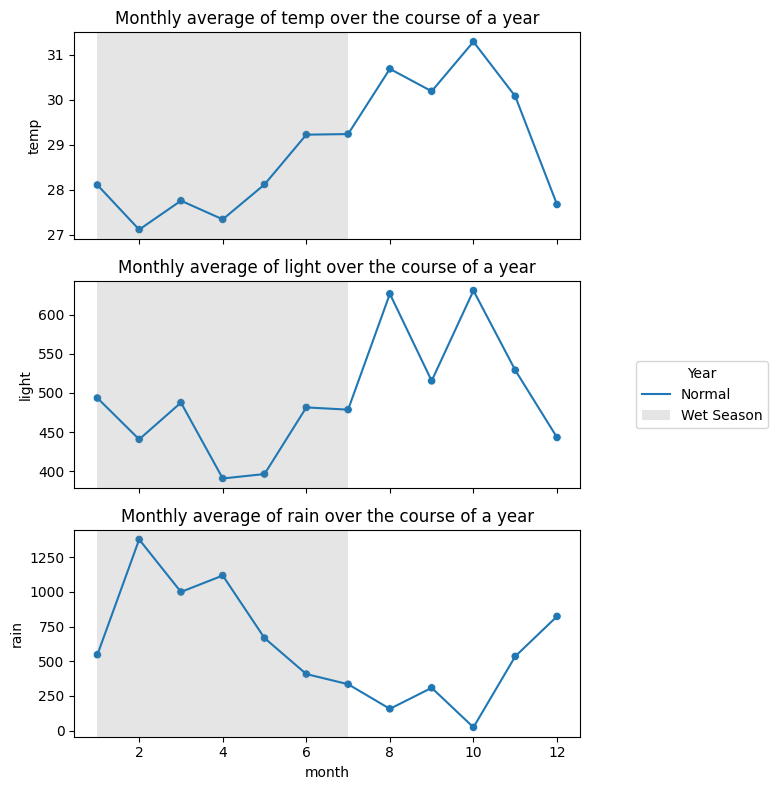

In [ ]:
# We'll use the function 'plot_monthly_data'. The arguments will be the monthly averaged data
# (data), the environmental variables we chose above (vars), and the years we want to look
# at (years). Today, we'll just look at the normal year, so we'll type year = ['Normal']

# Coding tip! Since we're specifying a value in column of a dataset (so only
# rows with 'Normal' in the 'yr_label' column) and not a specific object, we
# have to put it in both brackets and quotes ['']

plot_monthly_data(data = sapflow_month, vars = env_vars, years = ['Normal'])

# Troubleshoot: Did you get this error?
# TypeError: 'yr_label'
# You might have used 'climate' instead of 'climate_month'! The computer is getting
# confused since there is no 'yr_label' column in 'climate'

# Troubleshoot: Did you get this error?
# TypeError: only list-like objects are allowed to be passed to isin(), you passed a `str`
# Make sure your list of years is in brackets and quotes! ['Normal']

What do you notice about the monthly patterns during a normal year? Anything interesting with the environmental variables you chose? Now go back and pick new environmental variables!

The shaded part on the graph actually refers to the Amazon's **wet season**. In the tropics, instead of winter, spring, summer, and fall, the year is divided into a **wet season**, which gets a lot of rain, and the **dry season** where it rains a lot less. What do you notice about the differences between the wet and the dry season? How do you think this might impact sapflow?

***any other info about the wet and dry season we want to talk about?***

Now let's compare those results to a drought year! In the following code block that is copied from above, type ['Normal', 'Drought'] as the year argument.

How does the drought year compare to a normal year?

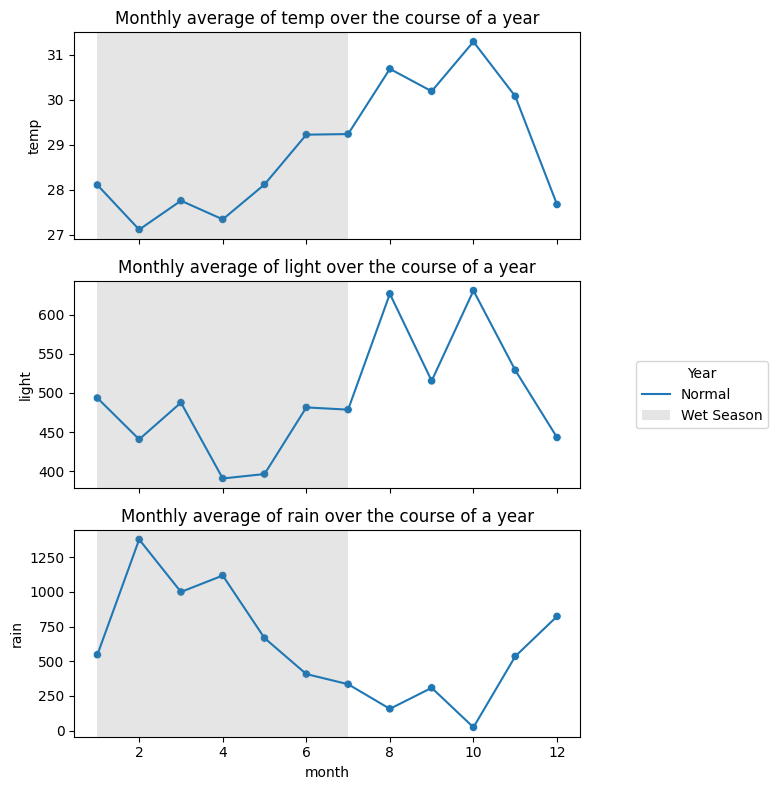

In [ ]:
# We'll use the function 'plot_monthly_data'. The arguments will be the monthly averaged data
# (data), the environmental variables we chose above (vars), and the years we want to look
# at (years). Today, we'll just look at the normal year, so we'll type year = ['Normal']

# Coding tip! Since we're specifying a value in column of a dataset (so only
# rows with 'Normal' in the 'yr_label' column) and not a specific object, we
# have to put it in both brackets and quotes ['']

plot_monthly_data(data =sapflow_month, vars = env_vars, years = ['Normal', 'Drought'])

# Troubleshoot: Did you get this error?
# TypeError: 'yr_label'
# You might have used 'data' instead of 'climate_month'! The computer is getting
# confused since there is no 'yr_label' column in 'data'

# Troubleshoot: Did you get this error?
# TypeError: only list-like objects are allowed to be passed to isin(), you passed a `str`
# Make sure your list of years is in brackets and quotes! ['Normal']

*** other learning questions here***